2025-07-24 19:32:22.741427: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1753385542.976811      19 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1753385543.042684      19 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
I0000 00:00:1753387493.843019      19 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1753387493.843736      19 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability:

Epoch 1/10


I0000 00:00:1753387500.086386      60 service.cc:148] XLA service 0x7a6018008710 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1753387500.087351      60 service.cc:156]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1753387500.087371      60 service.cc:156]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1753387500.399783      60 cuda_dnn.cc:529] Loaded cuDNN version 90300


  18/2539 ━━━━━━━━━━━━━━━━━━━━ 24s 10ms/step - accuracy: 0.4691 - loss: 0.7051

I0000 00:00:1753387502.571758      60 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


2539/2539 ━━━━━━━━━━━━━━━━━━━━ 31s 11ms/step - accuracy: 0.5253 - loss: 0.6912 - val_accuracy: 0.6256 - val_loss: 0.6682
Epoch 2/10
2539/2539 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.6197 - loss: 0.6520 - val_accuracy: 0.6619 - val_loss: 0.6224
Epoch 3/10
2539/2539 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.6711 - loss: 0.6067 - val_accuracy: 0.7426 - val_loss: 0.5254
Epoch 4/10
2539/2539 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.6887 - loss: 0.5878 - val_accuracy: 0.7787 - val_loss: 0.5067
Epoch 5/10
2539/2539 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.7005 - loss: 0.5759 - val_accuracy: 0.7856 - val_loss: 0.5001
Epoch 6/10
2539/2539 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.7030 - loss: 0.5710 - val_accuracy: 0.7712 - val_loss: 0.5007
Epoch 7/10
2539/2539 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.7027 - loss: 0.5705 - val_accuracy: 0.7724 - val_loss: 0.4946
Epoch 8/10
2539/2539 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.7040 - loss: 0.56

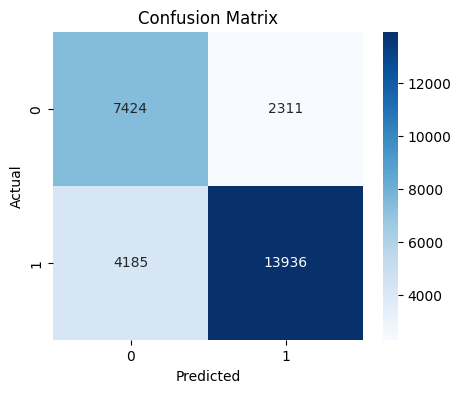


Classification Report:
               precision    recall  f1-score   support

           0     0.6395    0.7626    0.6957      9735
           1     0.8578    0.7691    0.8110     18121

    accuracy                         0.7668     27856
   macro avg     0.7486    0.7658    0.7533     27856
weighted avg     0.7815    0.7668    0.7707     27856

Sensitivity (Recall): 0.7691
Specificity: 0.7626


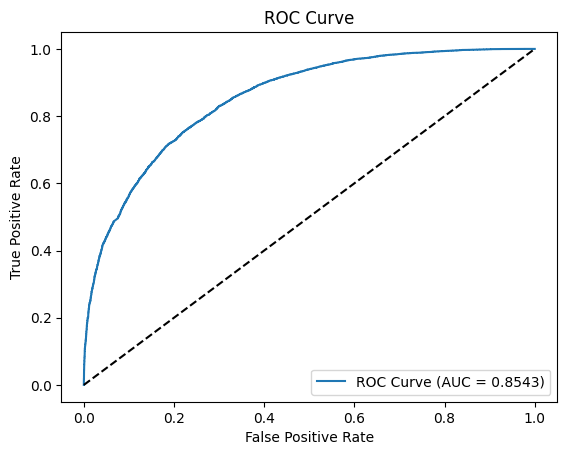

In [1]:
# 📦 Step 1: Import Libraries
import pandas as pd
import numpy as np
import ast
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv1D, GlobalMaxPooling1D, Dropout, Input
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

# 📂 Step 2: Load CSVs Without Header and Skip First Row
train_df = pd.read_csv('/kaggle/input/cyber-bullying-text-with-emojis/all_train.csv', header=None, skiprows=1)
val_df = pd.read_csv('/kaggle/input/cyber-bullying-text-with-emojis/all_val.csv', header=None, skiprows=1)
test_df = pd.read_csv('/kaggle/input/cyber-bullying-text-with-emojis/all_test.csv', header=None, skiprows=1)

# 📝 Step 3: Assign Column Names
column_names = ['text', 'features', 'level']
train_df.columns = column_names
val_df.columns = column_names
test_df.columns = column_names

# 🧹 Step 4: Remove invalid rows where 'features' is not a list
def is_valid_feature(row):
    try:
        parsed = ast.literal_eval(row)
        return isinstance(parsed, list)
    except:
        return False

train_df = train_df[train_df['features'].apply(is_valid_feature)]
val_df = val_df[val_df['features'].apply(is_valid_feature)]
test_df = test_df[test_df['features'].apply(is_valid_feature)]

# ✅ Step 5: Convert strings to array safely
def convert_str_to_array(column):
    return column.apply(lambda x: np.array(ast.literal_eval(x)))

X_train = np.stack(convert_str_to_array(train_df['features']))
y_train = train_df['level'].astype(int).values

X_val = np.stack(convert_str_to_array(val_df['features']))
y_val = val_df['level'].astype(int).values

X_test = np.stack(convert_str_to_array(test_df['features']))
y_test = test_df['level'].astype(int).values

# 🔁 Step 6: Reshape for CNN input
X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_val = X_val.reshape(X_val.shape[0], X_val.shape[1], 1)
X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

# 🧠 Step 7: CNN Model
model = Sequential([
    Input(shape=(X_train.shape[1], 1)),
    Conv1D(128, 5, activation='relu'),
    GlobalMaxPooling1D(),
    Dropout(0.5),
    Dense(64, activation='relu'),
    Dense(1, activation='sigmoid')
])
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# 🚀 Step 8: Train the Model
history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=10, batch_size=64)

# 📊 Step 9: Evaluate the Model
y_pred_prob = model.predict(X_test).ravel()
y_pred = (y_pred_prob > 0.5).astype(int)

# ✅ Accuracy
acc = accuracy_score(y_test, y_pred)
print("✅ Accuracy:", acc)

# ✅ Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ✅ Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred, digits=4))

# ✅ Sensitivity & Specificity
tn, fp, fn, tp = cm.ravel()
sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)
print(f"Sensitivity (Recall): {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")

# ✅ ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
roc_auc = roc_auc_score(y_test, y_pred_prob)

plt.figure()
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()


Random Forest

✅ Accuracy: 0.9813684663986215


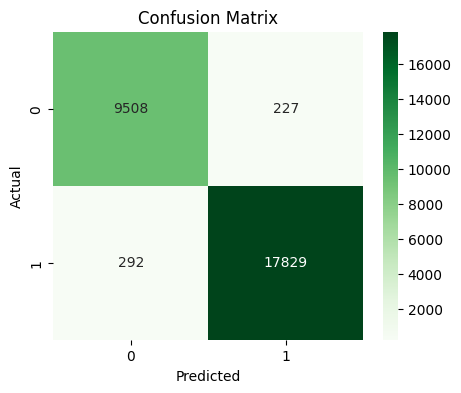


Classification Report:
               precision    recall  f1-score   support

           0     0.9702    0.9767    0.9734      9735
           1     0.9874    0.9839    0.9857     18121

    accuracy                         0.9814     27856
   macro avg     0.9788    0.9803    0.9795     27856
weighted avg     0.9814    0.9814    0.9814     27856

Sensitivity (Recall): 0.9839
Specificity: 0.9767


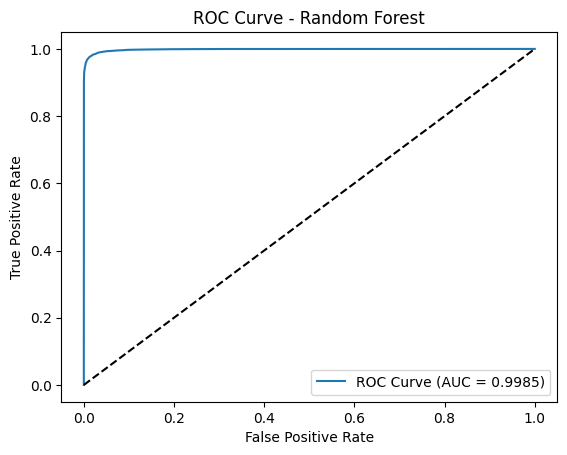

In [2]:
# 📦 Step 1: Import Libraries
import pandas as pd
import numpy as np
import ast
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

# 📂 Step 2: Load CSVs Without Header and Skip First Row
train_df = pd.read_csv('/kaggle/input/cyber-bullying-text-with-emojis/all_train.csv', header=None, skiprows=1)
val_df = pd.read_csv('/kaggle/input/cyber-bullying-text-with-emojis/all_val.csv', header=None, skiprows=1)
test_df = pd.read_csv('/kaggle/input/cyber-bullying-text-with-emojis/all_test.csv', header=None, skiprows=1)

# 📝 Step 3: Assign Column Names
column_names = ['text', 'features', 'level']
train_df.columns = column_names
val_df.columns = column_names
test_df.columns = column_names

# 🧹 Step 4: Remove invalid rows where 'features' is not a list
def is_valid_feature(row):
    try:
        parsed = ast.literal_eval(row)
        return isinstance(parsed, list)
    except:
        return False

train_df = train_df[train_df['features'].apply(is_valid_feature)]
val_df = val_df[val_df['features'].apply(is_valid_feature)]
test_df = test_df[test_df['features'].apply(is_valid_feature)]

# ✅ Step 5: Convert stringified feature vectors into NumPy arrays
def convert_str_to_array(column):
    return column.apply(lambda x: np.array(ast.literal_eval(x)))

X_train = np.stack(convert_str_to_array(train_df['features']))
y_train = train_df['level'].astype(int).values

X_val = np.stack(convert_str_to_array(val_df['features']))
y_val = val_df['level'].astype(int).values

X_test = np.stack(convert_str_to_array(test_df['features']))
y_test = test_df['level'].astype(int).values

# 🧠 Step 6: Train Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# 📊 Step 7: Evaluate the Model
y_pred = rf_model.predict(X_test)
y_pred_prob = rf_model.predict_proba(X_test)[:, 1]

# ✅ Accuracy
acc = accuracy_score(y_test, y_pred)
print("✅ Accuracy:", acc)

# ✅ Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ✅ Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred, digits=4))

# ✅ Sensitivity & Specificity
tn, fp, fn, tp = cm.ravel()
sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)
print(f"Sensitivity (Recall): {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")

# ✅ ROC Curve + AUC
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
roc_auc = roc_auc_score(y_test, y_pred_prob)

plt.figure()
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Random Forest')
plt.legend(loc='lower right')
plt.show()
